# Detecting emotions with ML algorithms 

**Course:** 5ARE0, Academic Year 2026/2027
**Assignment 2, Group 2**

| Name | Student number |
|---|---|
| Gabriele Salvo | 2140004 |
| Valērijs Gončarovs | 2565161 |
| Herman Chang | 2406748 |

**Deadline:** 25 October 2026, 23:59

---

## Objective

Build a tool that classifies a stretch of bicycle lane as **smooth** or **bumpy** from the
inertial sensors of a smartphone (accelerometer, gyroscope, gravity), recorded with the
*Sensor Logger* app while cycling.

The notebook implements the pipeline of Section 3 of the assignment brief and follows the
CRISP-DM phases:

| CRISP-DM phase | Notebook section |
|---|---|
| Business / Objective Understanding | 1 |
| Data Understanding | 2, 3 and 4 |
| Data Preparation | 5, 6 and 7 |
| Modelling | 8 and 9 |
| Evaluation | 8.5 to 8.11, 9.3 and 10 |
| Deployment | 11 |
| Conclusions and recommendations | 12 |

**How to run.** Put the raw Sensor Logger exports in `data/raw/` (naming convention in
Section 3) and the external dataset in `DeploymentData/`, select the `Python (group2)` kernel
and run *Kernel > Restart & Run All*. The notebook imports no local `.py` files. A full run
takes roughly 15 minutes on a laptop; the nested cross-validation of Section 8.10 is the
slowest step.

In [26]:
# Automatically re-import files when updated
%load_ext autoreload
%autoreload 2

In [27]:
import os
import joblib
import numpy as np
import pandas as pd
import dlib
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

PREDICTOR_PATH = "landmark_detectors/shape_predictor_68_face_landmarks.dat"
MODEL_PATH = "models"
N_LANDMARKS = 68
UPSCALE = 192

In [28]:
def load_fer2013_dataset(csv_path):
  df = pd.read_csv(csv_path)
  
  # Filter for the training split
  train_df = df[df['Usage'] == 'Training']
  val_df = df[df['Usage'] == 'PublicTest']
  test_df = df[df['Usage'] == 'PrivateTest']

  X_train, y_train = build_features(train_df)

  X_val, y_val = build_features(val_df)

  X_test, y_test = build_features(test_df)

  return X_train, y_train, X_val, y_val, X_test, y_test

In [29]:
def build_features(df):
    X = []
    y = df["emotion"].to_numpy(dtype=np.int64)
    failed = 0

    predictor = dlib.shape_predictor(PREDICTOR_PATH)

    for pixel_sequence in df["pixels"]:
        image = np.array(pixel_sequence.split(), dtype=np.uint8).reshape(48, 48)

        features, detected = extract_landmarks(image, predictor)
        X.append(features)

    return X, y


In [30]:
def extract_landmarks(image, predictor):
    """
    Extract 68 facial landmarks as raw (x, y) coordinates.

    Input:
        image: 48x48 grayscale image, values in [0, 255]
        predictor: dlib.shape_predictor object

    Output:
        Feature vector of shape (136,), x and y in [0, 1] relative to image size.
        Returns zeros if extraction fails.
    """
    try:
        image = np.asarray(image, dtype=np.uint8)

        # Resize only: no contrast or intensity changes
        upscaled_img = cv2.resize(image, (UPSCALE, UPSCALE), interpolation=cv2.INTER_CUBIC)

        # FER2013 images are already face crops, so skip the face detector and
        # pass the whole image to the predictor as the face rectangle.
        rect = dlib.rectangle(0, 0, UPSCALE - 1, UPSCALE - 1)
        shape = predictor(upscaled_img, rect)

        features = np.array(
            [[p.x / UPSCALE, p.y / UPSCALE] for p in shape.parts()],
            dtype=np.float32
        ).flatten()
        return features, True

    except Exception:
        return np.zeros(N_LANDMARKS * 2, dtype=np.float32), False

In [ ]:
X_train, y_train, X_val, y_val, X_test, y_test = (
    load_fer2013_dataset("fer2013.csv")
)

In [45]:
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1,
    bootstrap=True
)

param_grid = {
    "n_estimators":     [300, 500, 800],
    "max_depth":        [None, 20, 30, 40],
    "min_samples_leaf": [1, 2, 4, 8],
    "min_samples_split":[2, 5, 10],
    "max_features":     ["sqrt", "log2", 0.2, 0.35],
    "class_weight":     [None, "balanced", "balanced_subsample"],
    "max_samples":      [None, 0.7, 0.9],   # only used with bootstrap=True (the default)
}


grid_search = RandomizedSearchCV(
    rf_model,
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_val, y_val)

print("Best parameters:", grid_search.best_params_)
print("Best CV macro F1:", round(grid_search.best_score_, 4))

c:\Users\Legion Pro\miniconda3\Lib\site-packages\sklearn\model_selection\_search.py:1237: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best parameters: {'n_estimators': 800, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_samples': 0.7, 'max_features': 0.2, 'max_depth': 30, 'class_weight': 'balanced'}
Best CV macro F1: nan


In [46]:
rf_model = RandomForestClassifier(
    n_estimators=grid_search.best_params_["n_estimators"],
    max_depth=grid_search.best_params_["max_depth"],
    min_samples_leaf=grid_search.best_params_["min_samples_leaf"],
    min_samples_split=grid_search.best_params_["min_samples_split"],
    max_features=grid_search.best_params_["max_features"],
    class_weight=grid_search.best_params_["class_weight"],
    max_samples=grid_search.best_params_["max_samples"],
    random_state=42,
    n_jobs=-1,
    bootstrap=True
)
    

In [35]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

param_grid = {
    "lr__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    "lr__solver": ["lbfgs", "saga"],
    "lr__class_weight": [None, "balanced"],
    "lr__tol": [1e-4, 1e-3],
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_val, y_val)

print("Best parameters:", grid_search.best_params_)
print("Best CV macro F1:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters: {'lr__C': 10.0, 'lr__class_weight': None, 'lr__solver': 'saga', 'lr__tol': 0.001}
Best CV macro F1: 0.4126


In [36]:
lr_model = LogisticRegression(
    C=grid_search.best_params_["lr__C"],
    solver=grid_search.best_params_["lr__solver"],
    class_weight=grid_search.best_params_["lr__class_weight"],
    tol=grid_search.best_params_["lr__tol"],
    max_iter=5000,
    random_state=42
)

In [37]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        probability=False,
        random_state=42
    ))
])

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1],
    "svm__class_weight": [None, "balanced"],
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

svm_search.fit(X_val, y_val)

print("Best parameters:", svm_search.best_params_)
print("Best CV macro F1:", round(svm_search.best_score_, 4))

Fitting 5 folds for each of 32 candidates, totalling 160 fits


c:\Users\Legion Pro\miniconda3\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best parameters: {'svm__C': 100, 'svm__class_weight': 'balanced', 'svm__gamma': 0.001}
Best CV macro F1: 0.3939


In [38]:
svm_model = SVC(
    C=svm_search.best_params_["svm__C"],
    gamma=svm_search.best_params_["svm__gamma"],
    class_weight=svm_search.best_params_["svm__class_weight"],
    kernel="rbf",
    probability=False,
    random_state=42
)

In [39]:
os.makedirs(MODEL_PATH, exist_ok=True)

# Save Random Forest model
model_file = os.path.join(MODEL_PATH, "rf_for_fer2013.pkl")
joblib.dump(rf_model, model_file)

# Save Logistic Regression model
model_file = os.path.join(MODEL_PATH, "lr_for_fer2013.pkl")
joblib.dump(lr_model, model_file)

# Save SVM model
model_file = os.path.join(MODEL_PATH, "svm_for_fer2013.pkl")
joblib.dump(svm_model, model_file)

['models\\svm_for_fer2013.pkl']

In [40]:
rf_model.fit(X_train, y_train)

# Validation evaluation
rf_val_pred = rf_model.predict(X_val)

print("Random Forest Validation accuracy:", accuracy_score(y_val, rf_val_pred))
print("Random Forest Validation macro F1:", f1_score(y_val, rf_val_pred, average="macro"))

lr_model.fit(X_train, y_train)

# Validation evaluation
lr_val_pred = lr_model.predict(X_val)

print("Logistic Regression Validation accuracy:", accuracy_score(y_val, lr_val_pred))
print("Logistic Regression Validation macro F1:", f1_score(y_val, lr_val_pred, average="macro"))

svm_model.fit(X_train, y_train)

# Validation evaluation
svm_val_pred = svm_model.predict(X_val)

print("SVM Validation accuracy:", accuracy_score(y_val, svm_val_pred))
print("SVM Validation macro F1:", f1_score(y_val, svm_val_pred, average="macro"))

Random Forest Validation accuracy: 0.47534132070214546
Random Forest Validation macro F1: 0.43323726647969535
Logistic Regression Validation accuracy: 0.4845360824742268
Logistic Regression Validation macro F1: 0.3872430059162211


c:\Users\Legion Pro\miniconda3\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM Validation accuracy: 0.4140429088882697
SVM Validation macro F1: 0.3428697967534259


In [41]:
# Final test evaluation
rf_test_pred = rf_model.predict(X_test)

print("Random Forest Test accuracy:", accuracy_score(y_test, rf_test_pred))
print("Random Forest Test macro F1:", f1_score(y_test, rf_test_pred, average="macro"))

print("Classification Report — Random Forest on FER2013")
print(classification_report(
    y_test,
    rf_test_pred,
    labels=list(range(7)),
    target_names=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],
    zero_division=0
))

# Final test evaluation
lr_test_pred = lr_model.predict(X_test)

print("Logistic Regression Test accuracy:", accuracy_score(y_test, lr_test_pred))
print("Logistic Regression Test macro F1:", f1_score(y_test, lr_test_pred, average="macro"))

print("Classification Report — Logistic Regression on FER2013")
print(classification_report(
    y_test,
    lr_test_pred,
    labels=list(range(7)),
    target_names=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],
    zero_division=0
))

# Final test evaluation
svm_test_pred = svm_model.predict(X_test)

print("SVM Test accuracy:", accuracy_score(y_test, svm_test_pred))
print("SVM Test macro F1:", f1_score(y_test, svm_test_pred, average="macro"))

print("Classification Report — SVM on FER2013")
print(classification_report(
    y_test,
    svm_test_pred,
    labels=list(range(7)),
    target_names=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],
    zero_division=0
))

Random Forest Test accuracy: 0.4898300362217888
Random Forest Test macro F1: 0.4536142593794488
Classification Report — Random Forest on FER2013
              precision    recall  f1-score   support

       Angry       0.40      0.35      0.37       491
     Disgust       0.29      0.49      0.37        55
        Fear       0.41      0.23      0.30       528
       Happy       0.67      0.69      0.68       879
         Sad       0.35      0.37      0.36       594
    Surprise       0.58      0.63      0.60       416
     Neutral       0.45      0.56      0.50       626

    accuracy                           0.49      3589
   macro avg       0.45      0.47      0.45      3589
weighted avg       0.49      0.49      0.48      3589

Logistic Regression Test accuracy: 0.48704374477570356
Logistic Regression Test macro F1: 0.38931201150040906
Classification Report — Logistic Regression on FER2013
              precision    recall  f1-score   support

       Angry       0.39      0.35     

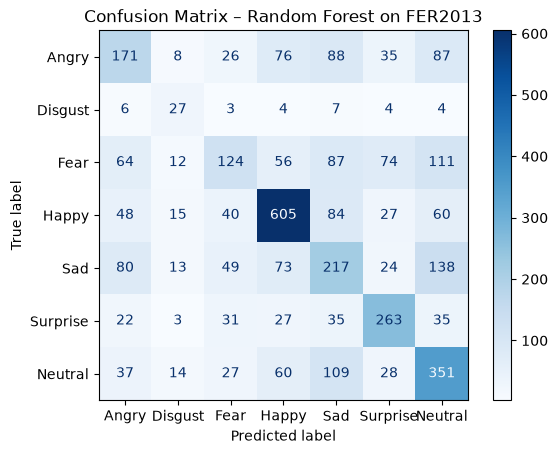

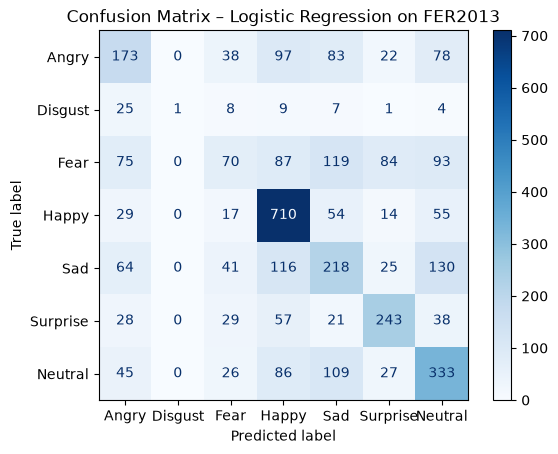

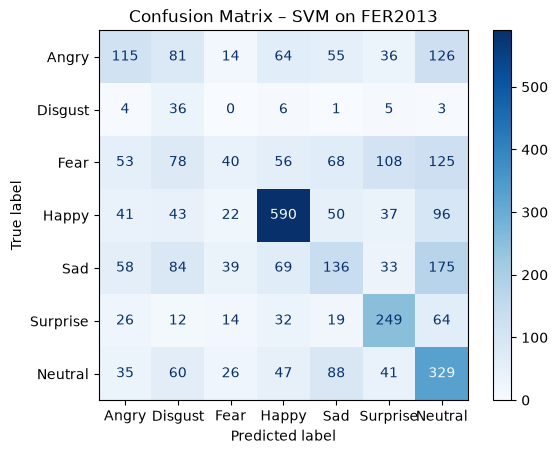

In [42]:
rf_score = confusion_matrix(y_test, rf_test_pred)
lr_score = confusion_matrix(y_test, lr_test_pred)
svm_score = confusion_matrix(y_test, svm_test_pred)

# Building a confusion matrix based on evaluation results
cm = ConfusionMatrixDisplay(
    rf_score, 
    display_labels=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],)
cm.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – Random Forest on FER2013")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()


cm = ConfusionMatrixDisplay(
    lr_score,
    display_labels=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],
)
cm.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – Logistic Regression on FER2013")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()


cm = ConfusionMatrixDisplay(
    svm_score,
    display_labels=[
        "Angry", "Disgust", "Fear", "Happy",
        "Sad", "Surprise", "Neutral"
    ],
)
cm.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – SVM on FER2013")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()